In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Варіант 1 — Київ
np.random.seed(1)

N = 1000

# Генеруємо випадкові точки в квадраті [0, 1] × [0, 1]
x = np.random.uniform(0, 1, N)
y = np.random.uniform(0, 1, N)

# Перевіряємо, які точки потрапили всередину чверті кола
inside = x**2 + y**2 <= 1

# Частка точок усередині фігури
fraction_inside = np.mean(inside)

# Площа квадрата дорівнює 1
square_area = 1

# Оцінка площі чверті кола
mc_estimate = fraction_inside * square_area

print("Кількість випробувань:", N)
print("Кількість точок усередині чверті кола:", np.sum(inside))
print(f"Частка точок усередині фігури: {fraction_inside:.6f}")
print(f"Оцінка площі методом Монте-Карло: {mc_estimate:.6f}")

Кількість випробувань: 1000
Кількість точок усередині чверті кола: 770
Частка точок усередині фігури: 0.770000
Оцінка площі методом Монте-Карло: 0.770000


In [2]:
# Точне значення площі чверті одиничного кола
exact_area = np.pi / 4

# Обчислення абсолютної та відносної похибок
absolute_error = abs(mc_estimate - exact_area)
relative_error = absolute_error / exact_area * 100

print(f"Точна площа: {exact_area:.6f}")
print(f"Оцінка Монте-Карло: {mc_estimate:.6f}")
print(f"Абсолютна похибка: {absolute_error:.6f}")
print(f"Відносна похибка: {relative_error:.4f}%")

Точна площа: 0.785398
Оцінка Монте-Карло: 0.770000
Абсолютна похибка: 0.015398
Відносна похибка: 1.9606%


In [3]:
# Точна площа чверті одиничного кола
exact_area = np.pi / 4

# Кількість випробувань для дослідження збіжності
sample_sizes = [100, 1000, 10000, 100000]
repeats = 200

# Фіксуємо генератор випадкових чисел перед циклом
np.random.seed(1)

results = []

for N in sample_sizes:
    errors = []

    for _ in range(repeats):
        x = np.random.uniform(0, 1, N)
        y = np.random.uniform(0, 1, N)

        inside = x**2 + y**2 <= 1
        estimate = np.mean(inside)

        error = abs(estimate - exact_area)
        errors.append(error)

    mean_error = np.mean(errors)
    results.append({
        "Кількість випробувань N": N,
        "Середня абсолютна похибка": mean_error
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 Кількість випробувань N  Середня абсолютна похибка
                     100                   0.035004
                    1000                   0.010357
                   10000                   0.003336
                  100000                   0.001061


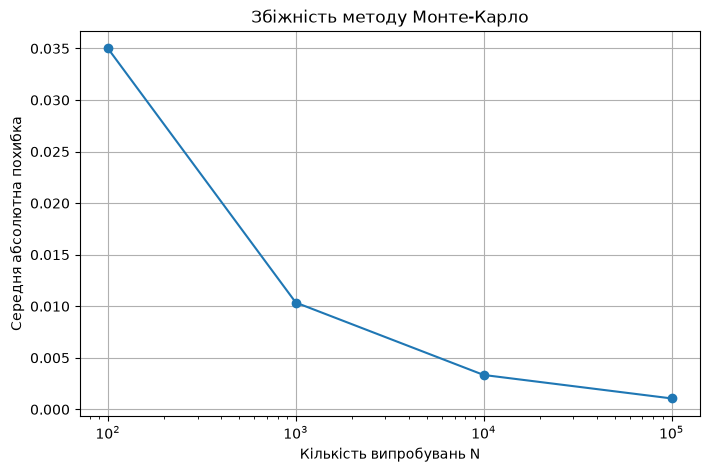

In [4]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Кількість випробувань N"],
    results_df["Середня абсолютна похибка"],
    marker="o"
)

plt.xscale("log")
plt.xlabel("Кількість випробувань N")
plt.ylabel("Середня абсолютна похибка")
plt.title("Збіжність методу Монте-Карло")
plt.grid(True)

plt.show()

**Аналіз графіка.**

Зі збільшенням кількості випробувань середня абсолютна похибка загалом зменшується. Це свідчить про збіжність методу Монте-Карло. Приблизно похибка зменшується пропорційно \(1/\sqrt{N}\). Тому збільшення кількості випробувань у 10 разів зазвичай зменшує похибку приблизно у \(\sqrt{10}\approx3{,}16\) раза. Фактичні значення можуть відрізнятися через випадковий характер моделювання.

## Завдання 5. Контрольні запитання

**1. Чому оцінка площі методом Монте-Карло є вибірковим середнім і як закон великих чисел гарантує збіжність?**

Оцінка площі є вибірковим середнім індикаторів потрапляння випадкових точок усередину фігури. Індикатор дорівнює 1, якщо точка потрапила всередину фігури, і 0 — якщо ні. Середнє цих значень дорівнює частці точок усередині фігури. За законом великих чисел зі збільшенням кількості незалежних випробувань ця частка наближається до ймовірності потрапляння точки всередину фігури. Тому оцінка площі наближається до точного значення.

**2. Чому збільшення кількості випробувань у 4 рази зменшує похибку приблизно в 2 рази, а не в 4?**

Стандартна похибка методу Монте-Карло зазвичай пропорційна \(1/\sqrt{N}\), де \(N\) — кількість випробувань. Якщо збільшити \(N\) у 4 рази, то похибка зменшиться приблизно у \(\sqrt{4}=2\) рази. Щоб зменшити похибку приблизно в 10 разів, потрібно збільшити кількість випробувань орієнтовно у 100 разів.

**3. Чому для оцінювання площі потрібно помножити частку точок усередині фігури на площу обмежувального прямокутника?**

Якщо точки рівномірно генеруються в обмежувальному прямокутнику, частка точок усередині фігури наближено дорівнює відношенню площі фігури до площі прямокутника. Тому площу фігури можна оцінити як добуток цієї частки на площу прямокутника. У цій роботі площа квадрата дорівнює 1, тому оцінка площі чверті кола дорівнює самій частці точок усередині неї.

**4. Чому для задач на математичне сподівання потрібно використовувати `min(axis=1)` або `max(axis=1)`, а не просто `min()` чи `max()`?**

Якщо кожен рядок масиву відповідає окремому випробуванню, параметр `axis=1` дає мінімум або максимум у кожному рядку окремо. У результаті отримуємо значення для всіх випробувань і можемо обчислити їхнє середнє. Використання `min()` або `max()` без зазначення осі для всього масиву повертає одне глобальне значення, яке не відображає результати окремих випробувань.

## Висновок

Під час практичної роботи було реалізовано метод Монте-Карло для оцінювання площі чверті одиничного кола. Отриману оцінку порівняно з точним значенням \(\pi/4\), обчислено абсолютну та відносну похибки. За допомогою повторних експериментів досліджено залежність середньої абсолютної похибки від кількості випробувань і побудовано графік збіжності. Результати демонструють, що зі збільшенням кількості випробувань оцінка зазвичай стає точнішою. Це узгоджується із законом великих чисел і закономірністю зменшення стандартної похибки приблизно пропорційно \(1/\sqrt{N}\).